# 🏀 NBA Player Performance Analysis
### By Anant Bhatnagar

## Project Overview
In this project I analyze NBA player statistics spanning multiple seasons.
I explore scoring trends, team performance, and player efficiency
using Python, Pandas, and Matplotlib.

## Questions I will answer:
- Who are the top 10 scorers of all time?
- Which teams have the best average stats?
- How has scoring changed over the decades?
- Which position scores the most?

In [35]:
import pandas as pd 
import matplotlib.pyplot as plt 
import seaborn as sns

# Make charts look nice
sns.set_theme(style='whitegrid')
plt.rcParams['figure.figsize'] = (12, 6)

print("Libraries loaded!")

Libraries loaded!


In [36]:
# Load the NBA dataset
df = pd.read_csv('nba.csv')

# How big is it?
print("Shape", df.shape)

# What columns do we have?
print("\nColumns:")
print(df.columns.tolist())


# First 5 rows
print("\nFirst 5 players:")
df.head()

Shape (12844, 22)

Columns:
['Unnamed: 0', 'player_name', 'team_abbreviation', 'age', 'player_height', 'player_weight', 'college', 'country', 'draft_year', 'draft_round', 'draft_number', 'gp', 'pts', 'reb', 'ast', 'net_rating', 'oreb_pct', 'dreb_pct', 'usg_pct', 'ts_pct', 'ast_pct', 'season']

First 5 players:


,Unnamed: 0,player_name,team_abbreviation,age,player_height,player_weight,college,country,draft_year,draft_round,...,pts,reb,ast,net_rating,oreb_pct,dreb_pct,usg_pct,ts_pct,ast_pct,season
0,0,Randy Livingston,HOU,22.0,193.04,94.800728,Louisiana State,USA,1996,2,...,3.9,1.5,2.4,0.3,0.042,0.071,0.169,0.487,0.248,1996-97
1,1,Gaylon Nickerson,WAS,28.0,190.50,86.182480,Northwestern Oklahoma,USA,1994,2,...,3.8,1.3,0.3,8.9,0.030,0.111,0.174,0.497,0.043,1996-97
2,2,George Lynch,VAN,26.0,203.20,103.418976,North Carolina,USA,1993,1,...,8.3,6.4,1.9,-8.2,0.106,0.185,0.175,0.512,0.125,1996-97
3,3,George McCloud,LAL,30.0,203.20,102.058200,Florida State,USA,1989,1,...,10.2,2.8,1.7,-2.7,0.027,0.111,0.206,0.527,0.125,1996-97
4,4,George Zidek,DEN,23.0,213.36,119.748288,UCLA,USA,1995,1,...,2.8,1.7,0.3,-14.1,0.102,0.169,0.195,0.500,0.064,1996-97


In [37]:
# Check for missing  values in each column
print("Missing values per colunmn:")
print(df.isnull().sum())


Missing values per colunmn:
Unnamed: 0              0
player_name             0
team_abbreviation       0
age                     0
player_height           0
player_weight           0
college              1854
country                 0
draft_year              0
draft_round             0
draft_number            0
gp                      0
pts                     0
reb                     0
ast                     0
net_rating              0
oreb_pct                0
dreb_pct                0
usg_pct                 0
ts_pct                  0
ast_pct                 0
season                  0
dtype: int64


In [38]:
# ── Step 2: Clean the Data ──
# drop() → removes a column from the table
# columns=['Unnamed: 0'] → tells it WHICH column to remove
# df = → saves the result back into df
df = df.drop(columns=['Unnamed: 0'])
df['college'] = df['college'].fillna('No College')

# isnull() → checks every cell → empty = True, has value = False
# .sum() → counts how many True values per column
print(df.isnull().sum())



player_name          0
team_abbreviation    0
age                  0
player_height        0
player_weight        0
college              0
country              0
draft_year           0
draft_round          0
draft_number         0
gp                   0
pts                  0
reb                  0
ast                  0
net_rating           0
oreb_pct             0
dreb_pct             0
usg_pct              0
ts_pct               0
ast_pct              0
season               0
dtype: int64


In [39]:
# ── Step 3: Find Top 10 Scorers ─────────────

# groupby() → groups all rows by player name
# so all seasons for LeBron are grouped together
grouped = df.groupby('player_name')

# ['pts'] → look at the points column only
# .mean() → calculate average points per game
#            across all their seasons
avg_pts = grouped['pts'].mean()

# sort_values() → sort from highest to lowest
# ascending=False → highest number comes first
top10 = avg_pts.sort_values(ascending=False)

# .head(10) -> Keep only the 10 players
top10 = top10.head(10)
print("🏀 Top 10 Scorers (Career Average Points Per Game):")
print(top10)




🏀 Top 10 Scorers (Career Average Points Per Game):
player_name
Luka Doncic         27.700000
Kevin Durant        27.233333
LeBron James        27.200000
Joel Embiid         26.542857
Allen Iverson       26.064286
Trae Young          25.720000
Damian Lillard      25.500000
Michael Jordan      25.300000
Zion Williamson     25.166667
Donovan Mitchell    24.816667
Name: pts, dtype: float64


/var/folders/5r/tm156_f55xndmmr8mxl7dk6c0000gn/T/ipykernel_6266/1869384870.py:32: UserWarning: Glyph 127936 (\N{BASKETBALL AND HOOP}) missing from font(s) Arial.
  plt.tight_layout()
/opt/anaconda3/lib/python3.14/site-packages/IPython/core/pylabtools.py:170: UserWarning: Glyph 127936 (\N{BASKETBALL AND HOOP}) missing from font(s) Arial.
  fig.canvas.print_figure(bytes_io, **kw)


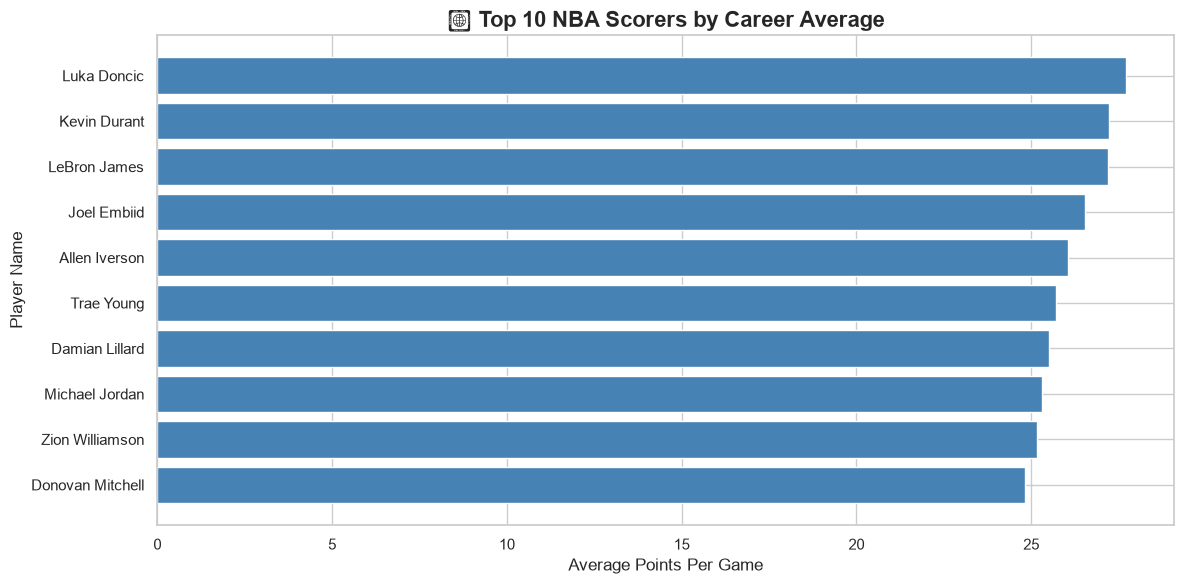

In [40]:
# ── Step 4: Visualize Top 10 Scorers ────────

# figure() → creates a new blank chart
# figsize=(12,6) → sets the size
#   12 → width in inches
#   6  → height in inches]
plt.figure(figsize=(12,6))

# barh() → draws a horizontal bar chart
# top10.values → the points values (numbers)
# top10.index  → the player names (labels)
# color        → color of the bars
plt.barh(top10.index, top10.values, color='steelblue')

# invert_yaxis() → flips the chart so
# highest scorer appears at TOP not bottom
plt.gca().invert_yaxis()


# title() → adds a title at the top of the chart
plt.title('🏀 Top 10 NBA Scorers by Career Average', 
          fontsize=16,        # size of the title text
          fontweight='bold')  # makes title bold

# xlabel() → adds a label below the x axis
plt.xlabel('Average Points Per Game', fontsize=12)

# ylabel() → adds a label on the left y axis
plt.ylabel('Player Name', fontsize=12)

# tight_layout() → makes sure nothing gets cut off
plt.tight_layout()



# show() -> displays the chart in the notebook
plt.show()







/var/folders/5r/tm156_f55xndmmr8mxl7dk6c0000gn/T/ipykernel_6266/3706232123.py:51: UserWarning: Glyph 128200 (\N{CHART WITH UPWARDS TREND}) missing from font(s) Arial.
  plt.tight_layout()
/opt/anaconda3/lib/python3.14/site-packages/IPython/core/pylabtools.py:170: UserWarning: Glyph 128200 (\N{CHART WITH UPWARDS TREND}) missing from font(s) Arial.
  fig.canvas.print_figure(bytes_io, **kw)


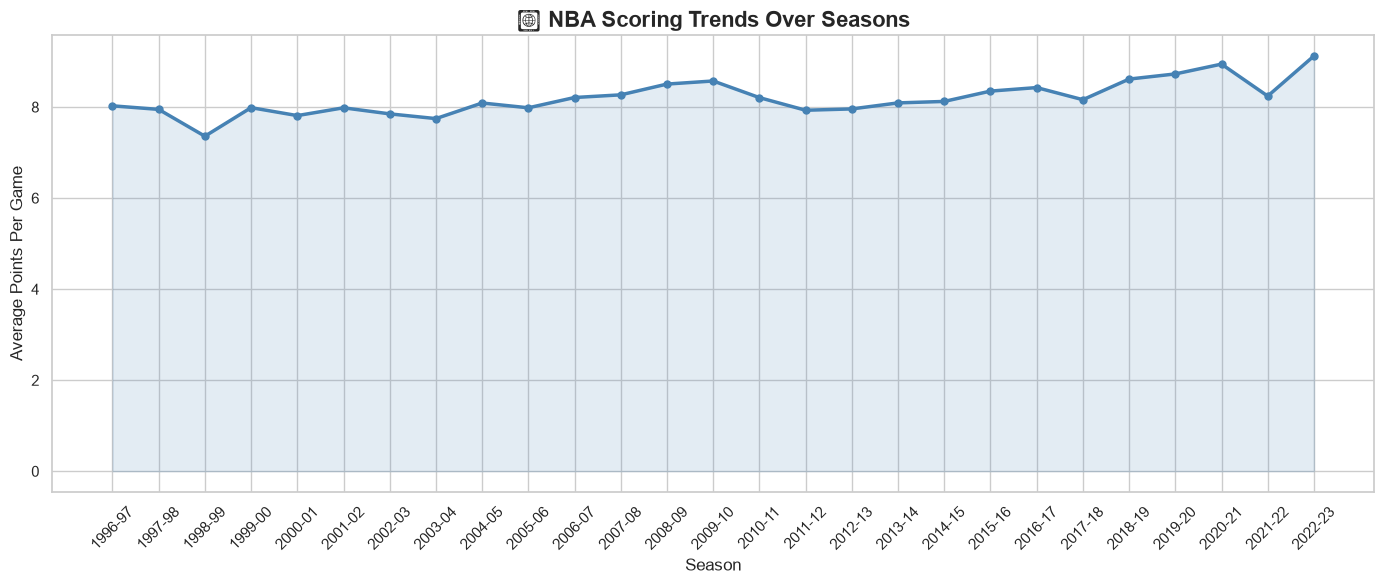

In [41]:
# ── Step 5: Scoring Trends Over Seasons ─────

# groupby('season') → groups all rows by season
# so all players in 1996-97 are grouped together
# all players in 1997-98 are grouped together etc.
season_pts = df.groupby('season')['pts'].mean()
# ['pts']  → look at points column only
# .mean()  → calculate average points per game
#             for ALL players that season

# ── Now draw the line chart ─────────────────

# figure() → create a new blank chart
# figsize=(14,6) → 14 inches wide, 6 inches tall
plt.figure(figsize=(14,6))



# plot() → draws a line chart
# season_pts.index  → the seasons (x axis)
# season_pts.values → the avg points (y axis)
# color='steelblue' → color of the line
# linewidth=2.5     → how thick the line is
# marker='o'        → adds a dot at each season
plt.plot(season_pts.index, season_pts.values, color = 'steelblue', linewidth = 2.5, marker = 'o', markersize = 5)


# fill the area under the line with light blue
# alpha=0.15 → how transparent the fill is
# 0 = invisible, 1 = fully solid
plt.fill_between(season_pts.index, season_pts.values, alpha = 0.15, color = 'steelblue')

# title() -> adds title at top of chart
plt.title('📈 NBA Scoring Trends Over Seasons',
          fontsize=16,
          fontweight='bold')

# xlabel() → label at the bottom
plt.xlabel('Season', fontsize = 12)

# ylabel() → label on the left
plt.ylabel('Average Points Per Game', fontsize = 12)


# xticks() → controls the x axis labels
# rotation=45 → rotates season labels 45 degrees
#               so they don't overlap each other
plt.xticks(rotation=45)

# tight_layout() → makes sure nothing gets cut off
plt.tight_layout()


# show() → displays chart in notebook
plt.show()




/var/folders/5r/tm156_f55xndmmr8mxl7dk6c0000gn/T/ipykernel_6266/2192966866.py:28: UserWarning: Glyph 127936 (\N{BASKETBALL AND HOOP}) missing from font(s) Arial.
  plt.tight_layout()


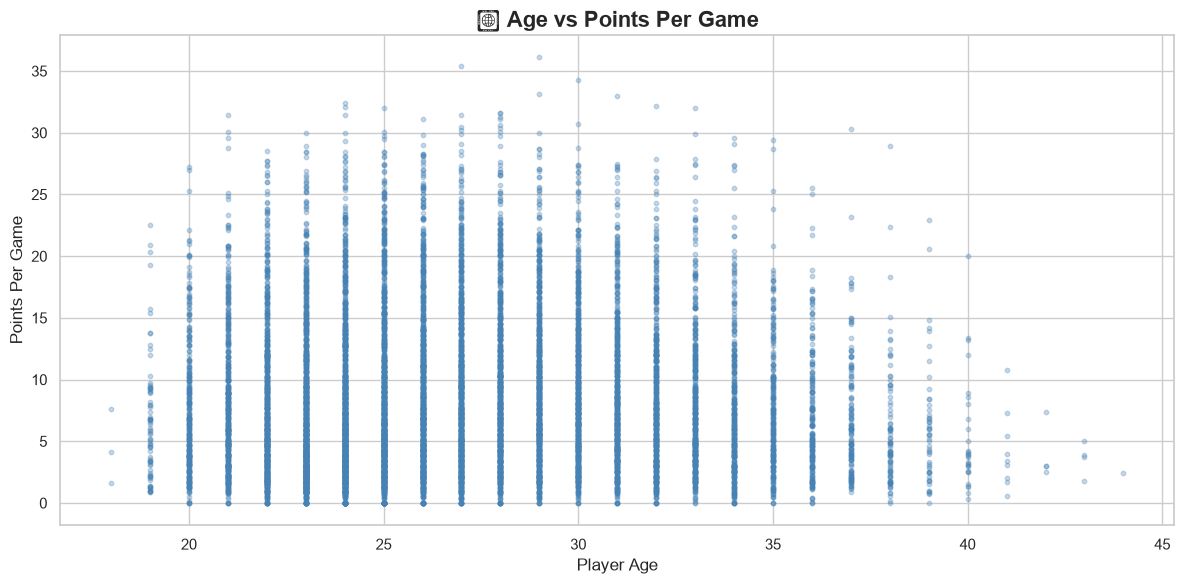

In [42]:
# ── Step 6: Age vs Points Scatter Plot ──────

# figure() → create a new blank chart
# figsize=(12,6) → 12 inches wide, 6 inches tall
plt.figure(figsize=(12,6))

# scatter() → draws a scatter plot
# df['age']    → age goes on x axis (bottom)
# df['pts']    → points goes on y axis (left)
# alpha=0.3    → makes dots 30% transparent
#                so overlapping dots are visible
# color        → color of the dots
# s=10         → size of each dot
#                smaller number = smaller dot
plt.scatter(df['age'], df['pts'], alpha = 0.3, color = 'steelblue', s = 10)

# title() → adds title at top
plt.title('🏀 Age vs Points Per Game', fontsize = 16, fontweight = 'bold')

# xlabel() → label at the bottom (x axis)
plt.xlabel('Player Age', fontsize = 12)

# ylabel() → label at the bottom (y axis)
plt.ylabel('Points Per Game', fontsize = 12)


# tight_layout() → makes sure nothing gets cut off
plt.tight_layout()


# show() → displays chart in notebook
plt.show()


In [43]:
# ── Step 7: Team Analysis ────────────────────

# groupby('team_abbreviation') → group all rows
# by team so all Lakers players are together
# all Warriors players are together etc.
team_pts = df.groupby('team_abbreviation')['pts'].mean()
# ['pts']  → look at points column only
# .mean()  → calculate average points
#             for each team


# sort_values() → sort from highest to lowest
# ascending=False → biggest number comes first
team_pts = team_pts.sort_values(ascending=False)

# head(10) -> keep only top 10 teams
top10_teams = team_pts.head(10)

print("🏀 Top 10 Teams by Average Points Per Game:")
print(top10_teams)



🏀 Top 10 Teams by Average Points Per Game:
team_abbreviation
NOP    9.068000
GSW    8.677230
LAL    8.628671
PHX    8.600723
BKN    8.564000
SAC    8.496411
HOU    8.465358
MIL    8.444965
DEN    8.434813
MIN    8.414388
Name: pts, dtype: float64


/var/folders/5r/tm156_f55xndmmr8mxl7dk6c0000gn/T/ipykernel_6266/1911334252.py:31: UserWarning: Glyph 127936 (\N{BASKETBALL AND HOOP}) missing from font(s) Arial.
  plt.tight_layout()


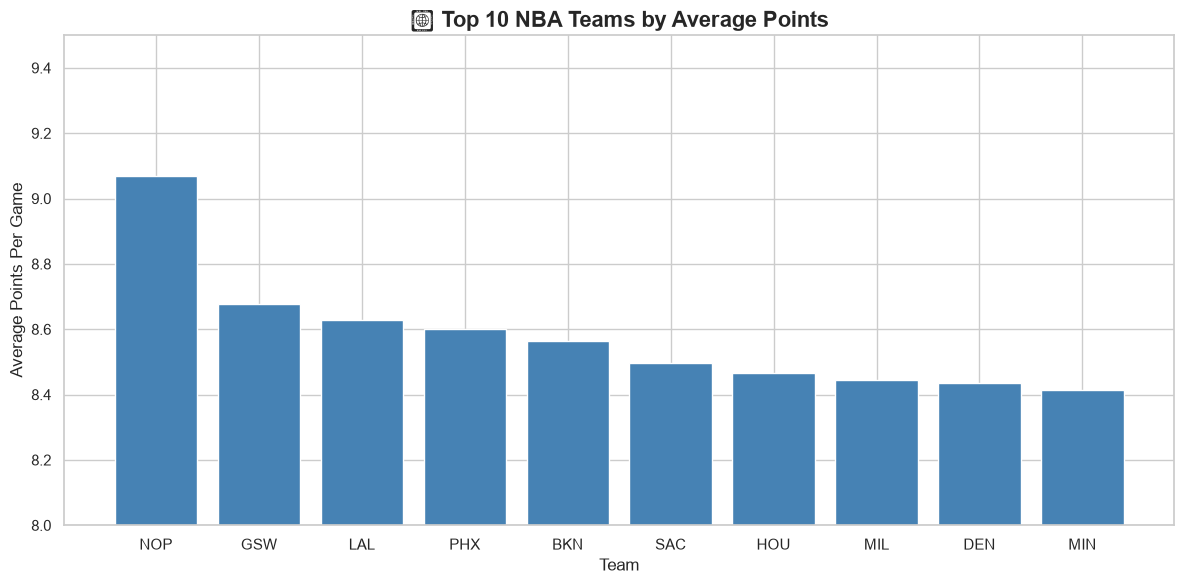

In [47]:
# ── Step 8: Visualize Top 10 Teams ──────────

# figure() → create a new blank chart
# figsize=(12,6) → 12 wide, 6 tall
plt.figure(figsize=(12,6))



# bar() → draws a vertical bar chart
# top10_teams.index  → team names on x axis
# top10_teams.values → points values on y axis
# color='steelblue'  → color of the bars
plt.bar(top10_teams.index, top10_teams.values, color = 'steelblue', edgecolor = 'white') 

# title() → adds title at top of chart
plt.title('🏀 Top 10 NBA Teams by Average Points', fontsize=16, fontweight='bold')


# xlabel() → label at the bottom
plt.xlabel('Team', fontsize=12)


# ylabel() → label on the left
plt.ylabel('Average Points Per Game', fontsize=12)


# ylim() → sets y axis range
plt.ylim(8, 9.5)

# tight_layout() → makes sure nothing gets cut off
plt.tight_layout()

# show() → displays chart in notebook
plt.show()



## 🔍 Key Insights

### 1. Top Scorers
- Luka Doncic has the higher NBA scorer in his NBA career, which  he averages about 27.7 points per game.
- Kevin Durant is the second highest NBA scorer in his NBA career, which he averages about 27.23 points per game.
- Lebron James is the third highest NBA scorer in his NBA career, which he averages about 27.20 points per game.


### 2. Scoring Trends Over Seasons
- NBA sccoring decreased from 1997 to 1999 due to the less game played during the season.
- Scoring has gotten better throughout the season from 2021 - 2023.


### 3. Age vs Points Per Game
- Most Player score more with the ages of 23-30 scoring 30 or higher points.
- As people age older, they score less points such as 10 to 15.


### 4. Top 10 Best Teams
- New Orleans Pelicans are the team that score the highest points overall.
- Golden State Warriors is the second team that score the highest points overall.
- All the top 10 teams score between 8.4 and 9.1 points per game.


